# MODUL PRAKTIKUM DATA MINING
## Association Rule Mining (Market Basket Analysis)

Notebook ini mengikuti urutan, struktur, nama variabel, fungsi, dan parameter kode pada **Modul Praktikum Data Mining – Association Rule Mining (Market Basket Analysis), 2026**, khususnya Bagian 4 (Langkah-Langkah Praktikum) dan Bagian 5 (Tugas Praktikum).

### Dataset yang digunakan
- `transactions_arm_praktikum.csv`: dataset transaksi mentah dengan kolom `TID` dan `Items`.
- `transactions_arm_praktikum_onehot.csv`: dataset transaksi dalam format one-hot dengan 12 kolom item.

Dataset berisi 60 transaksi dan 12 jenis item. Penyesuaian dari kode modul hanya dilakukan pada pemuatan data transaksi, karena modul menuliskan transaksi secara langsung dalam variabel `transactions`, sedangkan praktikum ini menggunakan file CSV yang dilampirkan. Kode analisis selanjutnya mengikuti kode pada modul.

## 4. Langkah-Langkah Praktikum
### 4.1 Persiapan Data Transaksi
Data transaksi dibaca dari CSV, kemudian kolom `Items` diubah menjadi *list of list* seperti format `transactions` pada modul.

In [1]:
%pip install -q mlxtend

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

# Membaca dataset transaksi mentah
data = pd.read_csv('transactions_arm_praktikum.csv')

# transactions: list berisi transaksi (daftar item per transaksi)
transactions = [items.split(', ') for items in data['Items']]

print('Jumlah transaksi:', len(transactions))
for i, t in enumerate(transactions[:5], 1):
    print(f'T{i}: {t}')

Jumlah transaksi: 60
T1: ['Gula', 'Kopi', 'Susu']
T2: ['Gula', 'Kopi', 'Susu']
T3: ['Mentega', 'Roti', 'Susu', 'Telur']
T4: ['Mie Instan']
T5: ['Keju', 'Roti', 'Susu', 'Telur']


Sebelum masuk ke algoritma Apriori, periksa frekuensi kemunculan tiap item terlebih dahulu, untuk mengenali item mana yang populer dan mana yang jarang dibeli:

In [21]:
from collections import Counter
cnt = Counter()
for t in transactions:
    cnt.update(t)
for item, freq in cnt.most_common():
    print(f'{item:12s}: {freq:2d} (support = {freq/len(transactions):.3f})')

Susu        : 19 (support = 0.317)
Roti        : 18 (support = 0.300)
Mie Instan  : 18 (support = 0.300)
Mentega     : 17 (support = 0.283)
Telur       : 15 (support = 0.250)
Sabun       : 15 (support = 0.250)
Gula        : 14 (support = 0.233)
Kopi        : 13 (support = 0.217)
Shampo      : 13 (support = 0.217)
Kecap       : 12 (support = 0.200)
Keju        :  6 (support = 0.100)
Teh         :  4 (support = 0.067)


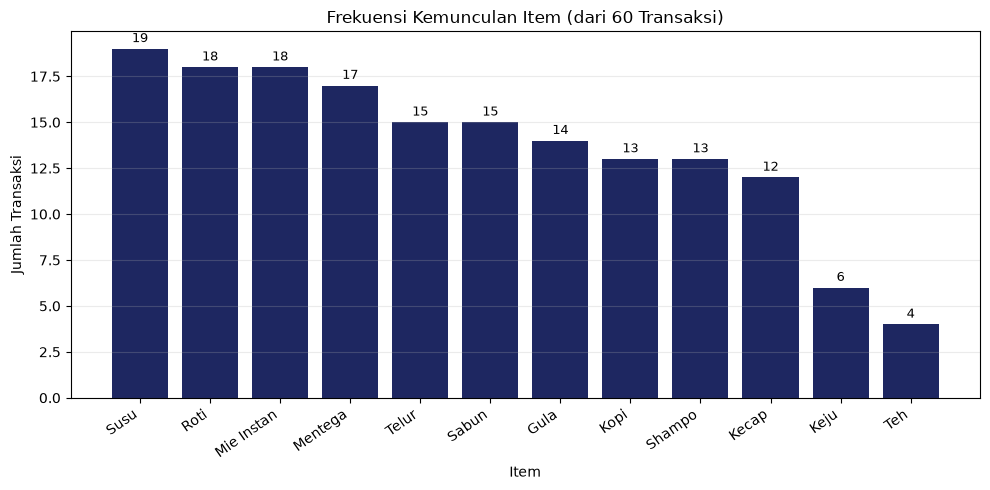

In [22]:
import matplotlib.pyplot as plt

items = [item for item, freq in cnt.most_common()]
frequencies = [freq for item, freq in cnt.most_common()]

plt.figure(figsize=(10, 5))
bars = plt.bar(items, frequencies, color='#1E2761')

plt.title('Frekuensi Kemunculan Item (dari 60 Transaksi)')
plt.xlabel('Item')
plt.ylabel('Jumlah Transaksi')
plt.xticks(rotation=35, ha='right')
plt.grid(axis='y', alpha=0.25)

# Menampilkan angka frekuensi di atas setiap batang
for bar, freq in zip(bars, frequencies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.2,
        str(freq),
        ha='center',
        va='bottom',
        fontsize=9
    )

plt.tight_layout()
plt.show()

### 4.2 Encoding Data Transaksi ke Format One-Hot
Kode encoding berikut mengikuti modul. Setelah itu, hasil encoding dibandingkan dengan file one-hot yang juga dilampirkan.

In [23]:
te = TransactionEncoder()
te_ary = te.fit(transactions).transform(transactions)
df = pd.DataFrame(te_ary, columns=te.columns_)

print('Ukuran matriks one-hot:', df.shape)
print(df.iloc[:5, :6])

Ukuran matriks one-hot: (60, 12)
    Gula  Kecap   Keju   Kopi  Mentega  Mie Instan
0   True  False  False   True    False       False
1   True  False  False   True    False       False
2  False  False  False  False     True       False
3  False  False  False  False    False        True
4  False  False   True  False    False       False


In [24]:
# Membaca dataset one-hot yang dilampirkan untuk memeriksa kesesuaian hasil encoding
df_onehot = pd.read_csv('transactions_arm_praktikum_onehot.csv')

# Menyamakan urutan kolom sebelum dibandingkan
df_onehot = df_onehot.reindex(columns=df.columns)

print('Ukuran dataset one-hot terlampir:', df_onehot.shape)
print('Apakah hasil encoding sama dengan dataset one-hot terlampir?',
      df.equals(df_onehot.astype(bool)))

Ukuran dataset one-hot terlampir: (60, 12)
Apakah hasil encoding sama dengan dataset one-hot terlampir? True


### 4.3 Mencari Frequent Itemset dengan Algoritma Apriori
Kode berikut menggunakan nilai `min_support = 0.15` seperti pada modul.

In [25]:
MIN_SUP = 0.15
freq_apriori = apriori(df, min_support=MIN_SUP, use_colnames=True)
freq_apriori = freq_apriori.sort_values('support', ascending=False)
print('Jumlah frequent itemset:', len(freq_apriori))
print(freq_apriori.to_string(index=False))

Jumlah frequent itemset: 17
 support              itemsets
0.316667                (Susu)
0.300000                (Roti)
0.300000          (Mie Instan)
0.283333             (Mentega)
0.250000               (Sabun)
0.250000               (Telur)
0.233333                (Gula)
0.216667              (Shampo)
0.216667                (Kopi)
0.216667          (Susu, Roti)
0.216667       (Mentega, Roti)
0.200000               (Kecap)
0.183333       (Mentega, Susu)
0.183333 (Mentega, Susu, Roti)
0.166667   (Telur, Mie Instan)
0.150000   (Kecap, Mie Instan)
0.150000       (Shampo, Sabun)


### 4.4 Membentuk Aturan Asosiasi
Aturan asosiasi dibentuk dengan `min_confidence = 0.5`, kemudian diurutkan berdasarkan Lift tertinggi, sesuai modul.

In [27]:
MIN_CONF = 0.5
rules = association_rules(freq_apriori, metric='confidence', min_threshold=MIN_CONF)
rules = rules.sort_values('lift', ascending=False).reset_index(drop=True)

print('Jumlah aturan asosiasi:', len(rules))

cols = ['antecedents', 'consequents', 'support', 'confidence', 'lift']
display(rules[cols].round(3))

Jumlah aturan asosiasi: 18


,antecedents,consequents,support,confidence,lift
0,"(Mentega, Susu)",(Roti),0.183,1.000,3.333
1,(Roti),"(Mentega, Susu)",0.183,0.611,3.333
2,(Mentega),"(Susu, Roti)",0.183,0.647,2.986
3,"(Susu, Roti)",(Mentega),0.183,0.846,2.986
4,(Sabun),(Shampo),0.150,0.600,2.769
5,(Shampo),(Sabun),0.150,0.692,2.769
6,(Susu),"(Mentega, Roti)",0.183,0.579,2.672
7,"(Mentega, Roti)",(Susu),0.183,0.846,2.672
8,(Mentega),(Roti),0.217,0.765,2.549
9,(Roti),(Mentega),0.217,0.722,2.549


### 4.5 Visualisasi Hasil
Scatter plot Support vs Confidence dengan ukuran dan warna bubble menunjukkan nilai Lift, sesuai kode pada modul.

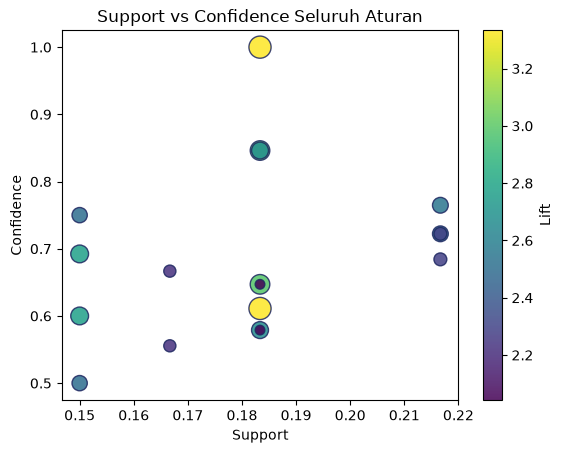

In [28]:
import matplotlib.pyplot as plt

sizes = (rules['lift'] - rules['lift'].min() + 0.3) * 160
sc = plt.scatter(rules['support'], rules['confidence'], s=sizes,
                 c=rules['lift'], cmap='viridis', alpha=0.85, edgecolor='#1E2761')
plt.colorbar(sc, label='Lift')
plt.xlabel('Support'); plt.ylabel('Confidence')
plt.title('Support vs Confidence Seluruh Aturan')
plt.show()

### 4.6 Interpretasi Bisnis dari Aturan Terpilih
Tampilkan sepuluh aturan dengan Lift tertinggi untuk membantu memilih aturan yang akan diinterpretasikan. Rekomendasi bisnis harus didasarkan pada hasil aktual dataset.

In [29]:
cols = ['antecedents', 'consequents', 'support', 'confidence', 'lift']
print(rules[cols].head(10).round(3).to_string(index=False))

    antecedents     consequents  support  confidence  lift
(Mentega, Susu)          (Roti)    0.183       1.000 3.333
         (Roti) (Mentega, Susu)    0.183       0.611 3.333
      (Mentega)    (Susu, Roti)    0.183       0.647 2.986
   (Susu, Roti)       (Mentega)    0.183       0.846 2.986
        (Sabun)        (Shampo)    0.150       0.600 2.769
       (Shampo)         (Sabun)    0.150       0.692 2.769
         (Susu) (Mentega, Roti)    0.183       0.579 2.672
(Mentega, Roti)          (Susu)    0.183       0.846 2.672
      (Mentega)          (Roti)    0.217       0.765 2.549
         (Roti)       (Mentega)    0.217       0.722 2.549


**Panduan interpretasi sesuai modul:**
- Aturan dengan Lift tinggi menunjukkan item pada antecedent dan consequent cenderung dibeli bersama.
- Aturan dapat diterjemahkan menjadi rekomendasi penataan rak, bundling promo, atau rekomendasi produk (*cross-selling*).
- Aturan asosiasi menunjukkan korelasi, bukan hubungan sebab-akibat.

### 4.7 Eksperimen: Pengaruh Nilai `min_support`
Kode berikut mengikuti daftar nilai dan proses eksperimen pada modul.

In [33]:
sweep_sup = [0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40]
for s in sweep_sup:
    fi = apriori(df, min_support=s, use_colnames=True)
    r = association_rules(fi, metric='confidence', min_threshold=0.5) if len(fi) else pd.DataFrame()
    print(f'min_support={s:.2f}: {len(fi):2d} itemset, {len(r):2d} aturan')

min_support=0.10: 19 itemset, 20 aturan
min_support=0.15: 17 itemset, 18 aturan
min_support=0.20: 12 itemset,  4 aturan
min_support=0.25:  6 itemset,  0 aturan
min_support=0.30:  3 itemset,  0 aturan
min_support=0.35:  0 itemset,  0 aturan
min_support=0.40:  0 itemset,  0 aturan


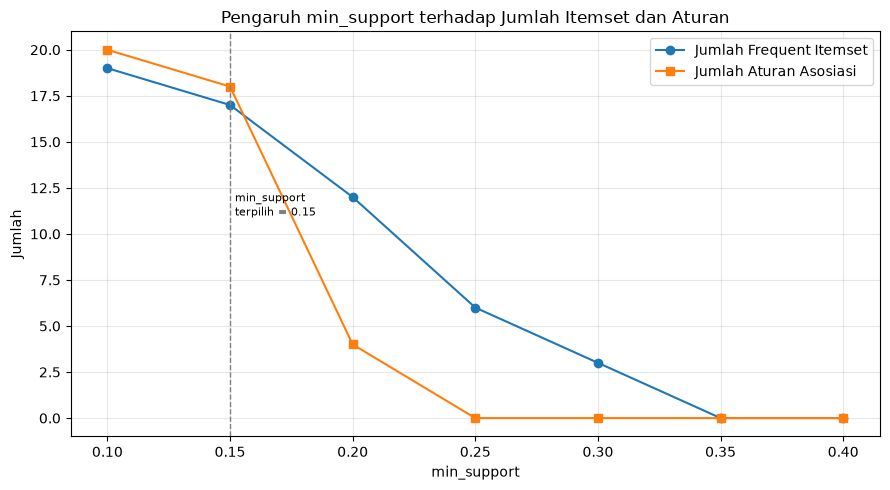

In [34]:
# Grafik Pengaruh Nilai min_support
jumlah_itemset = []
jumlah_aturan = []

for s in sweep_sup:
    fi = apriori(df, min_support=s, use_colnames=True)
    r = association_rules(fi, metric='confidence', min_threshold=0.5) if len(fi) else pd.DataFrame()

    jumlah_itemset.append(len(fi))
    jumlah_aturan.append(len(r))

plt.figure(figsize=(9, 5))

plt.plot(sweep_sup, jumlah_itemset, marker='o',
         label='Jumlah Frequent Itemset')

plt.plot(sweep_sup, jumlah_aturan, marker='s',
         label='Jumlah Aturan Asosiasi')

plt.axvline(x=0.15, color='gray', linestyle='--', linewidth=1)

plt.text(0.152, max(jumlah_itemset + jumlah_aturan) * 0.55,
         'min_support\nterpilih = 0.15', fontsize=8)

plt.xlabel('min_support')
plt.ylabel('Jumlah')
plt.title('Pengaruh min_support terhadap Jumlah Itemset dan Aturan')
plt.xticks(sweep_sup)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### 4.8 Eksperimen: Apriori vs FP-Growth
Kode berikut membandingkan jumlah frequent itemset dan waktu eksekusi kedua algoritma pada `min_support = 0.15`, sesuai modul.

In [35]:
import time

t0 = time.perf_counter()
freq_apriori = apriori(df, min_support=0.15, use_colnames=True)
t_apriori = time.perf_counter() - t0

t0 = time.perf_counter()
freq_fpgrowth = fpgrowth(df, min_support=0.15, use_colnames=True)
t_fpgrowth = time.perf_counter() - t0

set_apriori = set(frozenset(s) for s in freq_apriori['itemsets'])
set_fpgrowth = set(frozenset(s) for s in freq_fpgrowth['itemsets'])
print(f'Apriori : {len(freq_apriori)} itemset, {t_apriori*1000:.2f} ms')
print(f'FP-Growth: {len(freq_fpgrowth)} itemset, {t_fpgrowth*1000:.2f} ms')
print('Itemset identik?', set_apriori == set_fpgrowth)

Apriori : 17 itemset, 4.15 ms
FP-Growth: 17 itemset, 2.57 ms
Itemset identik? True


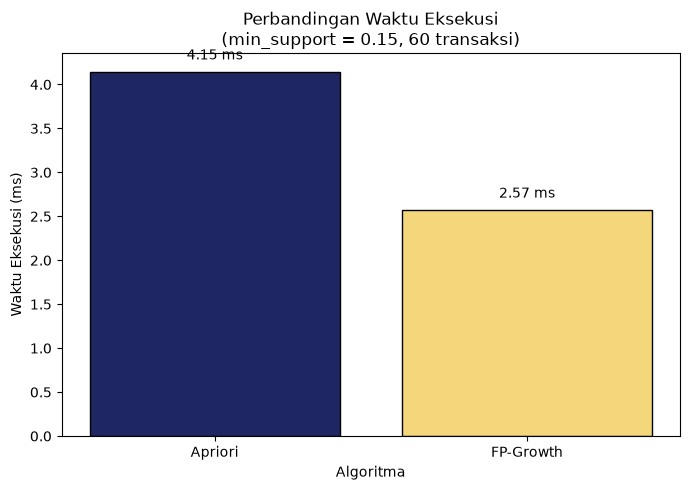

In [36]:
# Grafik Perbandingan Waktu Eksekusi Apriori vs FP-Growth

algoritma = ['Apriori', 'FP-Growth']
waktu = [t_apriori * 1000, t_fpgrowth * 1000]

plt.figure(figsize=(7, 5))

bars = plt.bar(
    algoritma,
    waktu,
    color=['#1E2761', '#F4D77A'],
    edgecolor='black'
)

plt.ylabel('Waktu Eksekusi (ms)')
plt.xlabel('Algoritma')
plt.title('Perbandingan Waktu Eksekusi\n(min_support = 0.15, 60 transaksi)')

# Menampilkan nilai waktu di atas batang
for bar, value in zip(bars, waktu):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.1,
        f'{value:.2f} ms',
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.show()

# 5. Tugas Praktikum

## 5.1 Tugas 1 — Eksplorasi Ambang Batas `min_support` dan `min_confidence`

### 1. Jalankan Apriori dengan `min_support = 0.10` dan `min_confidence = 0.5`, lalu bandingkan dengan hasil Bagian 4.3–4.4.

In [37]:
freq_apriori_010 = apriori(df, min_support=0.10, use_colnames=True)
rules_010 = association_rules(freq_apriori_010, metric='confidence', min_threshold=0.5)

print('min_support = 0.10')
print('Jumlah frequent itemset:', len(freq_apriori_010))
print('Jumlah aturan asosiasi:', len(rules_010))
print('\nPembanding min_support = 0.15')
freq_apriori_015 = apriori(df, min_support=0.15, use_colnames=True)
rules_015 = association_rules(freq_apriori_015, metric='confidence', min_threshold=0.5)
print('Jumlah frequent itemset:', len(freq_apriori_015))
print('Jumlah aturan asosiasi:', len(rules_015))

min_support = 0.10
Jumlah frequent itemset: 19
Jumlah aturan asosiasi: 20

Pembanding min_support = 0.15
Jumlah frequent itemset: 17
Jumlah aturan asosiasi: 18


### 2. Naikkan `min_confidence` menjadi 0.7. Catat aturan yang masih lolos dan aturan yang gugur.

In [38]:
rules_conf_070 = association_rules(freq_apriori_015, metric='confidence', min_threshold=0.7)

print('Jumlah aturan pada min_confidence = 0.5:', len(rules_015))
print('Jumlah aturan pada min_confidence = 0.7:', len(rules_conf_070))

rules_015['rule'] = rules_015['antecedents'].astype(str) + ' -> ' + rules_015['consequents'].astype(str)
rules_conf_070['rule'] = rules_conf_070['antecedents'].astype(str) + ' -> ' + rules_conf_070['consequents'].astype(str)

print('\nAturan yang masih lolos:')
print(rules_conf_070[['rule', 'support', 'confidence', 'lift']].round(3).to_string(index=False))

print('\nAturan yang gugur:')
print(rules_015[~rules_015['rule'].isin(rules_conf_070['rule'])][['rule', 'support', 'confidence', 'lift']].round(3).to_string(index=False))

Jumlah aturan pada min_confidence = 0.5: 18
Jumlah aturan pada min_confidence = 0.7: 7

Aturan yang masih lolos:
                                                 rule  support  confidence  lift
    frozenset({'Kecap'}) -> frozenset({'Mie Instan'})    0.150       0.750 2.500
        frozenset({'Mentega'}) -> frozenset({'Roti'})    0.217       0.765 2.549
        frozenset({'Roti'}) -> frozenset({'Mentega'})    0.217       0.722 2.549
           frozenset({'Roti'}) -> frozenset({'Susu'})    0.217       0.722 2.281
frozenset({'Mentega', 'Susu'}) -> frozenset({'Roti'})    0.183       1.000 3.333
frozenset({'Mentega', 'Roti'}) -> frozenset({'Susu'})    0.183       0.846 2.672
frozenset({'Susu', 'Roti'}) -> frozenset({'Mentega'})    0.183       0.846 2.986

Aturan yang gugur:
                                                 rule  support  confidence  lift
    frozenset({'Mie Instan'}) -> frozenset({'Kecap'})    0.150       0.500 2.500
        frozenset({'Mentega'}) -> frozenset({'Susu'})    

### 3. Buat grafik sweep `min_confidence` dengan `min_support = 0.15`.

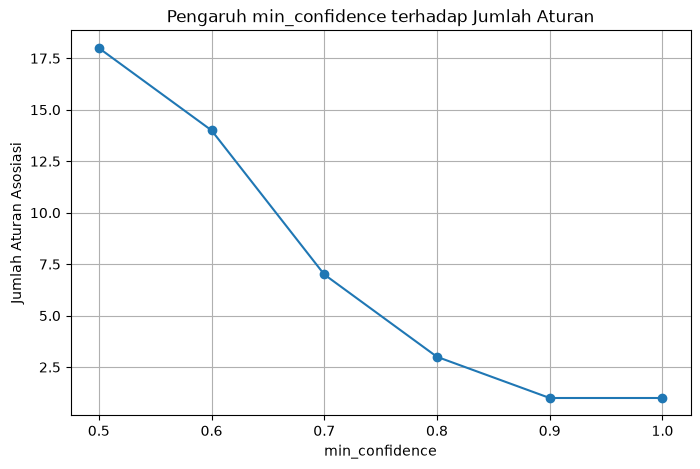

In [39]:
sweep_conf = [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
jumlah_rules = []

for c in sweep_conf:
    r = association_rules(freq_apriori_015, metric='confidence', min_threshold=c)
    jumlah_rules.append(len(r))

plt.figure(figsize=(8, 5))
plt.plot(sweep_conf, jumlah_rules, marker='o')
plt.xlabel('min_confidence')
plt.ylabel('Jumlah Aturan Asosiasi')
plt.title('Pengaruh min_confidence terhadap Jumlah Aturan')
plt.grid(True)
plt.show()

### 4. Diskusi trade-off
Gunakan jumlah aturan dari hasil eksperimen untuk membahas perbedaan ambang batas rendah dan tinggi. Ambang rendah menghasilkan lebih banyak aturan tetapi berisiko memuat pola yang kurang kuat, sedangkan ambang tinggi menghasilkan lebih sedikit aturan dengan confidence yang lebih tinggi.

## 5.2 Tugas 2 — Analisis Mendalam Aturan yang Belum Dibahas

Pilih dua aturan dari hasil `rules` yang belum dibahas pada Bagian 4.6 modul. Kode berikut menampilkan aturan beserta nilai leverage dan conviction agar dapat dipilih dan dianalisis.

In [40]:
cols_detail = ['antecedents', 'consequents', 'support', 'confidence', 'lift', 'leverage', 'conviction']
print(rules[cols_detail].round(3).to_string(index=False))

    antecedents     consequents  support  confidence  lift  leverage  conviction
(Mentega, Susu)          (Roti)    0.183       1.000 3.333     0.128         inf
         (Roti) (Mentega, Susu)    0.183       0.611 3.333     0.128       2.100
      (Mentega)    (Susu, Roti)    0.183       0.647 2.986     0.122       2.219
   (Susu, Roti)       (Mentega)    0.183       0.846 2.986     0.122       4.658
        (Sabun)        (Shampo)    0.150       0.600 2.769     0.096       1.958
       (Shampo)         (Sabun)    0.150       0.692 2.769     0.096       2.438
         (Susu) (Mentega, Roti)    0.183       0.579 2.672     0.115       1.860
(Mentega, Roti)          (Susu)    0.183       0.846 2.672     0.115       4.442
      (Mentega)          (Roti)    0.217       0.765 2.549     0.132       2.975
         (Roti)       (Mentega)    0.217       0.722 2.549     0.132       2.580
   (Mie Instan)         (Kecap)    0.150       0.500 2.500     0.090       1.600
        (Kecap)    (Mie Inst

Setelah menentukan dua aturan yang belum dibahas, masukkan indeks baris aturan yang dipilih pada kode berikut. Indeks mengikuti posisi baris pada tabel `rules`.

In [41]:
# Ganti angka indeks berikut dengan indeks dua aturan pilihan dari tabel rules
indeks_pilihan = [0, 1]

aturan_pilihan = rules.loc[indeks_pilihan, cols_detail]
print(aturan_pilihan.round(3).to_string(index=False))

    antecedents     consequents  support  confidence  lift  leverage  conviction
(Mentega, Susu)          (Roti)    0.183       1.000 3.333     0.128         inf
         (Roti) (Mentega, Susu)    0.183       0.611 3.333     0.128         2.1


**Panduan analisis:**
1. Leverage menunjukkan selisih antara support gabungan aktual dan support yang diharapkan jika kedua itemset independen.
2. Conviction digunakan untuk menilai kekuatan implikasi aturan.
3. Bandingkan leverage dan conviction dengan Lift.
4. Berikan interpretasi bisnis yang relevan untuk masing-masing aturan.

## 5.3 Tugas 3 — Perbandingan Apriori vs FP-Growth pada Ambang Lebih Rendah

Ulangi eksperimen Bagian 4.8 dengan `min_support = 0.05`.

In [42]:
t0 = time.perf_counter()
freq_apriori = apriori(df, min_support=0.05, use_colnames=True)
t_apriori = time.perf_counter() - t0

t0 = time.perf_counter()
freq_fpgrowth = fpgrowth(df, min_support=0.05, use_colnames=True)
t_fpgrowth = time.perf_counter() - t0

set_apriori = set(frozenset(s) for s in freq_apriori['itemsets'])
set_fpgrowth = set(frozenset(s) for s in freq_fpgrowth['itemsets'])
print(f'Apriori : {len(freq_apriori)} itemset, {t_apriori*1000:.2f} ms')
print(f'FP-Growth: {len(freq_fpgrowth)} itemset, {t_fpgrowth*1000:.2f} ms')
print('Itemset identik?', set_apriori == set_fpgrowth)

Apriori : 42 itemset, 5.23 ms
FP-Growth: 42 itemset, 3.20 ms
Itemset identik? True


Bandingkan jumlah itemset dan waktu eksekusi pada `min_support = 0.05` dengan hasil Bagian 4.8 (`min_support = 0.15`). Jelaskan apakah keunggulan FP-Growth semakin terlihat ketika jumlah itemset yang dicari semakin banyak.

## 5.4 Tugas 4 — Studi Kasus Mandiri

Dataset transaksi yang dilampirkan digunakan sebagai studi kasus toko kelontong. Dataset memenuhi syarat minimum pada modul, yaitu minimal 40 transaksi dan minimal 8 jenis item (dataset ini berisi 60 transaksi dan 12 jenis item). Jalankan pipeline encoding, Apriori, aturan asosiasi, dan visualisasi.

In [43]:
# Dataset studi kasus menggunakan data transaksi yang sama
print('Jumlah transaksi:', len(transactions))
print('Jumlah jenis item:', len(te.columns_))

# Menentukan ambang batas untuk studi kasus
MIN_SUP_STUDI = 0.15
MIN_CONF_STUDI = 0.5

freq_studi = apriori(df, min_support=MIN_SUP_STUDI, use_colnames=True)
rules_studi = association_rules(
    freq_studi, metric='confidence', min_threshold=MIN_CONF_STUDI
)
rules_studi = rules_studi.sort_values('lift', ascending=False).reset_index(drop=True)

print('Jumlah frequent itemset:', len(freq_studi))
print('Jumlah aturan asosiasi:', len(rules_studi))
print(rules_studi[['antecedents', 'consequents', 'support', 'confidence', 'lift']].round(3).to_string(index=False))

Jumlah transaksi: 60
Jumlah jenis item: 12
Jumlah frequent itemset: 17
Jumlah aturan asosiasi: 18
    antecedents     consequents  support  confidence  lift
(Mentega, Susu)          (Roti)    0.183       1.000 3.333
         (Roti) (Mentega, Susu)    0.183       0.611 3.333
      (Mentega)    (Susu, Roti)    0.183       0.647 2.986
   (Susu, Roti)       (Mentega)    0.183       0.846 2.986
        (Sabun)        (Shampo)    0.150       0.600 2.769
       (Shampo)         (Sabun)    0.150       0.692 2.769
         (Susu) (Mentega, Roti)    0.183       0.579 2.672
(Mentega, Roti)          (Susu)    0.183       0.846 2.672
         (Roti)       (Mentega)    0.217       0.722 2.549
      (Mentega)          (Roti)    0.217       0.765 2.549
   (Mie Instan)         (Kecap)    0.150       0.500 2.500
        (Kecap)    (Mie Instan)    0.150       0.750 2.500
         (Roti)          (Susu)    0.217       0.722 2.281
         (Susu)          (Roti)    0.217       0.684 2.281
        (Telur)  

### Visualisasi scatter plot dan bar chart Lift tertinggi

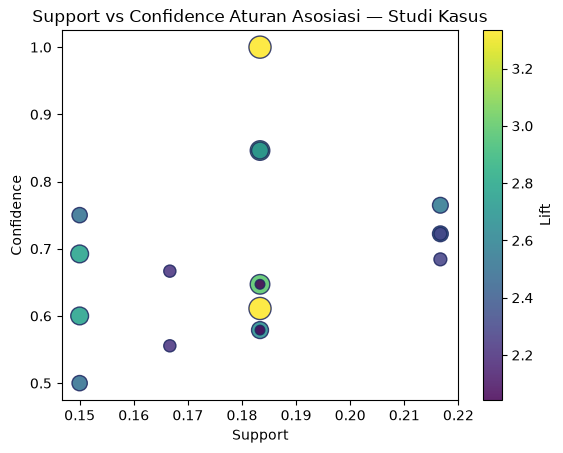

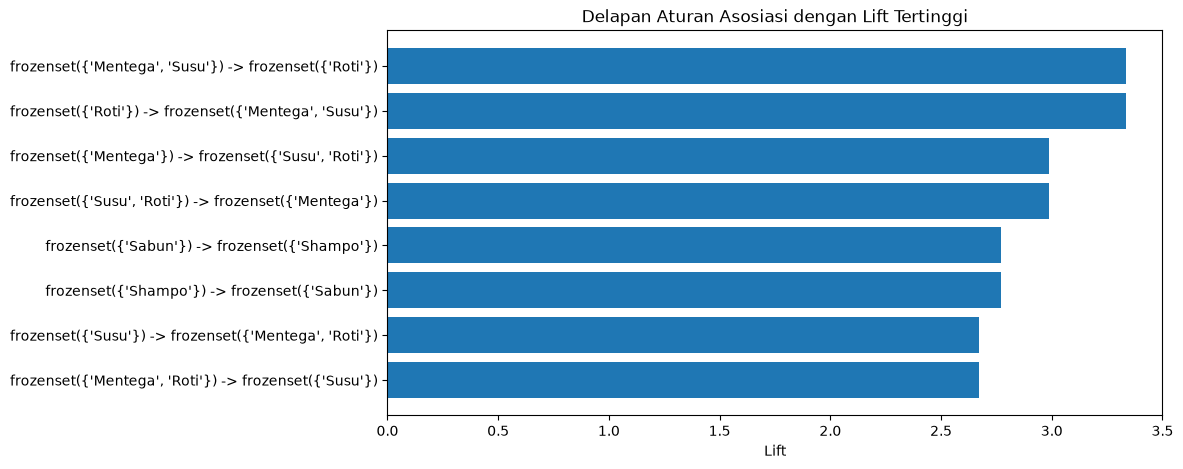

In [44]:
sizes = (rules_studi['lift'] - rules_studi['lift'].min() + 0.3) * 160
sc = plt.scatter(rules_studi['support'], rules_studi['confidence'], s=sizes,
                 c=rules_studi['lift'], cmap='viridis', alpha=0.85, edgecolor='#1E2761')
plt.colorbar(sc, label='Lift')
plt.xlabel('Support'); plt.ylabel('Confidence')
plt.title('Support vs Confidence Aturan Asosiasi — Studi Kasus')
plt.show()

top_rules = rules_studi.head(8).copy()
top_rules['rule'] = top_rules['antecedents'].astype(str) + ' -> ' + top_rules['consequents'].astype(str)

plt.figure(figsize=(10, 5))
plt.barh(top_rules['rule'][::-1], top_rules['lift'][::-1])
plt.xlabel('Lift')
plt.title('Delapan Aturan Asosiasi dengan Lift Tertinggi')
plt.show()

### Rekomendasi Bisnis
Berdasarkan aturan dengan Lift tertinggi, tuliskan minimal tiga rekomendasi bisnis konkret. Rekomendasi dapat berupa:
- Penataan produk pada rak yang berdekatan.
- Bundling promo untuk kombinasi produk yang sering dibeli bersama.
- Rekomendasi *cross-selling* pada saat pelanggan memilih suatu produk.

Pastikan setiap rekomendasi menyebutkan aturan aktual dari hasil dataset dan tidak menganggap asosiasi sebagai hubungan sebab-akibat.